Completed 100,000,000 / 1,000,000,000 paths (77.2s)
Completed 200,000,000 / 1,000,000,000 paths (155.4s)
Completed 300,000,000 / 1,000,000,000 paths (232.1s)
Completed 400,000,000 / 1,000,000,000 paths (308.8s)
Completed 500,000,000 / 1,000,000,000 paths (386.3s)
Completed 600,000,000 / 1,000,000,000 paths (463.7s)
Completed 700,000,000 / 1,000,000,000 paths (540.8s)
Completed 800,000,000 / 1,000,000,000 paths (617.2s)
Completed 900,000,000 / 1,000,000,000 paths (693.4s)
Completed 1,000,000,000 / 1,000,000,000 paths (770.2s)

Done in 770.2s
Theoretical Std Dev at step 100: 10.000000
Empirical Std Dev   at step 100: 9.999692


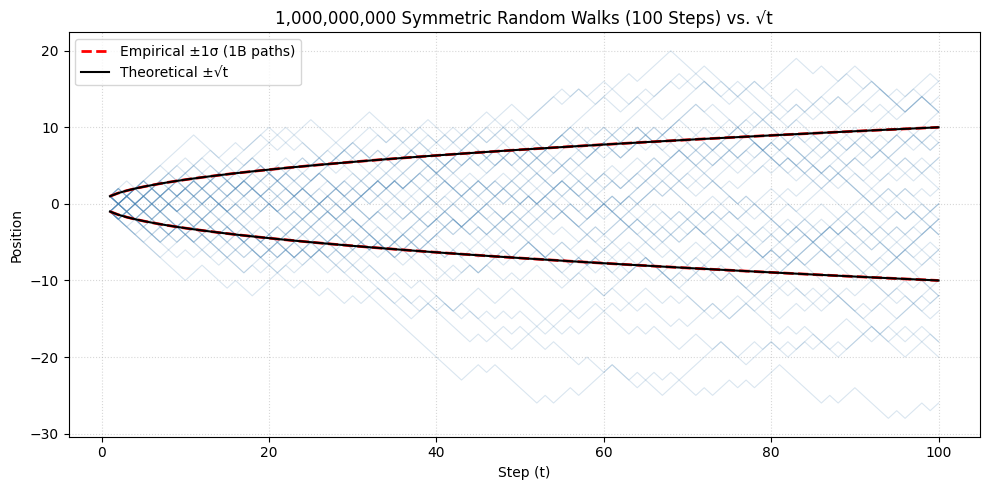

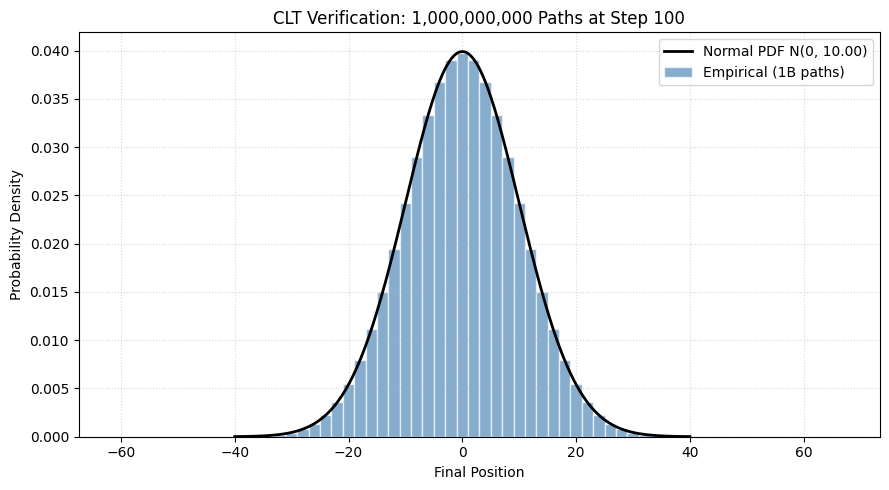

In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

n_paths = 1_000_000_000  # 1 billion paths
n_steps = 100
chunk_size = 1_000_000   # 1 million paths per batch
n_chunks = n_paths // chunk_size

# Running accumulators (int64 holds up to 9.2e18, zero overflow here)
sum_x = np.zeros(n_steps, dtype=np.int64)
sum_x2 = np.zeros(n_steps, dtype=np.int64)
final_counts = np.zeros(2 * n_steps + 1, dtype=np.int64)  # Covers positions -100 to +100
sample_paths = None

start = time.time()

for i in range(n_chunks):
    # Generate -1/+1 steps in-place using 1-byte int8
    steps = rng.integers(0, 2, size=(chunk_size, n_steps), dtype=np.int8)
    steps *= 2
    steps -= 1

    # Cumulative walk (int16 safely handles up to ±32,767 steps)
    paths = np.cumsum(steps, axis=1, dtype=np.int16)

    # Save 40 paths from the first chunk for Plot 1
    if i == 0:
        sample_paths = paths[:40].copy()

    # Accumulate step-by-step sums and squared sums across all paths
    sum_x += paths.sum(axis=0, dtype=np.int64)
    sum_x2 += (paths.astype(np.int32) ** 2).sum(axis=0, dtype=np.int64)

    # Accumulate exact final-position histogram counts (shift by +n_steps so min index = 0)
    final_counts += np.bincount(paths[:, -1] + n_steps, minlength=2 * n_steps + 1)

    if (i + 1) % 100 == 0:
        elapsed = time.time() - start
        print(f"Completed {(i + 1) * chunk_size:,} / {n_paths:,} paths ({elapsed:.1f}s)")

# Compute exact empirical std dev at every step t = 1..100
emp_var = (sum_x2 - (sum_x.astype(np.float64) ** 2) / n_paths) / (n_paths - 1)
emp_std = np.sqrt(emp_var)

t = np.arange(1, n_steps + 1)
theo_std = np.sqrt(t)

print(f"\nDone in {time.time() - start:.1f}s")
print(f"Theoretical Std Dev at step {n_steps}: {theo_std[-1]:.6f}")
print(f"Empirical Std Dev   at step {n_steps}: {emp_std[-1]:.6f}")

# --- PLOT 1: Sample Walks + sqrt(t) Envelope ---
plt.figure(figsize=(10, 5))
plt.plot(t, sample_paths.T, color='steelblue', alpha=0.2, linewidth=0.8)
plt.plot(t, emp_std, color='red', linestyle='--', linewidth=2.0, label='Empirical ±1σ (1B paths)')
plt.plot(t, -emp_std, color='red', linestyle='--', linewidth=2.0)
plt.plot(t, theo_std, color='black', linewidth=1.5, label='Theoretical ±√t')
plt.plot(t, -theo_std, color='black', linewidth=1.5)

plt.title('1,000,000,000 Symmetric Random Walks (100 Steps) vs. √t')
plt.xlabel('Step (t)')
plt.ylabel('Position')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# --- PLOT 2: CLT Bell Curve at Step 100 ---
positions = np.arange(-n_steps, n_steps + 1)
mask = final_counts > 0  # Only even positions (-100, -98, ..., +100) are reachable in 100 steps
# Divide probability by bar width (2) so total area = 1, matching the continuous Normal PDF
density = (final_counts[mask] / n_paths) / 2.0

sigma_final = np.sqrt(n_steps)
x = np.linspace(-4 * sigma_final, 4 * sigma_final, 400)
normal_pdf = (1 / (sigma_final * np.sqrt(2 * np.pi))) * np.exp(-0.5 * (x / sigma_final) ** 2)

plt.figure(figsize=(9, 5))
plt.bar(positions[mask], density, width=2.0, alpha=0.65, color='steelblue', edgecolor='white', label='Empirical (1B paths)')
plt.plot(x, normal_pdf, color='black', linewidth=2, label=f'Normal PDF N(0, {sigma_final:.2f})')
plt.title('CLT Verification: 1,000,000,000 Paths at Step 100')
plt.xlabel('Final Position')
plt.ylabel('Probability Density')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
